In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix,classification_report


In [2]:
df=pd.read_csv('/content/loan_approval_dataset.csv')
df

,loan_id,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,1,2,Graduate,No,9600000,29900000,12,778,2400000,17600000,22700000,8000000,Approved
1,2,0,Not Graduate,Yes,4100000,12200000,8,417,2700000,2200000,8800000,3300000,Rejected
2,3,3,Graduate,No,9100000,29700000,20,506,7100000,4500000,33300000,12800000,Rejected
3,4,3,Graduate,No,8200000,30700000,8,467,18200000,3300000,23300000,7900000,Rejected
4,5,5,Not Graduate,Yes,9800000,24200000,20,382,12400000,8200000,29400000,5000000,Rejected
...,...,...,...,...,...,...,...,...,...,...,...,...,...
4264,4265,5,Graduate,Yes,1000000,2300000,12,317,2800000,500000,3300000,800000,Rejected
4265,4266,0,Not Graduate,Yes,3300000,11300000,20,559,4200000,2900000,11000000,1900000,Approved
4266,4267,2,Not Graduate,No,6500000,23900000,18,457,1200000,12400000,18100000,7300000,Rejected
4267,4268,1,Not Graduate,No,4100000,12800000,8,780,8200000,700000,14100000,5800000,Approved


In [3]:
df.shape

(4269, 13)

In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-null   int64 
 11   bank_asset_value          4269 non-null   int64 
 12   loan_status               4269 non-null   object
dtypes: int64(10), object(3)
memory usage: 433.7+ KB


In [5]:
print(df.describe())

           loan_id   no_of_dependents   income_annum   loan_amount  \
count  4269.000000        4269.000000   4.269000e+03  4.269000e+03   
mean   2135.000000           2.498712   5.059124e+06  1.513345e+07   
std    1232.498479           1.695910   2.806840e+06  9.043363e+06   
min       1.000000           0.000000   2.000000e+05  3.000000e+05   
25%    1068.000000           1.000000   2.700000e+06  7.700000e+06   
50%    2135.000000           3.000000   5.100000e+06  1.450000e+07   
75%    3202.000000           4.000000   7.500000e+06  2.150000e+07   
max    4269.000000           5.000000   9.900000e+06  3.950000e+07   

         loan_term   cibil_score   residential_assets_value  \
count  4269.000000   4269.000000               4.269000e+03   
mean     10.900445    599.936051               7.472617e+06   
std       5.709187    172.430401               6.503637e+06   
min       2.000000    300.000000              -1.000000e+05   
25%       6.000000    453.000000               2.20000

In [6]:
df[' education']=df[' education'].map({' Graduate':1,' Not Graduate':0})
df[' education']

,education
0,1
1,0
2,1
3,1
4,0
...,...
4264,1
4265,0
4266,0
4267,0


In [7]:
#str.strip() is use for remove the extra space from the given column data
#map() is use for convert the categorical data to numeric data like 0 and 1
df.columns = df.columns.str.strip()
df['self_employed'] = df['self_employed'].str.strip().map({'Yes': 1, 'No': 0})
df['self_employed']

,self_employed
0,0
1,1
2,0
3,0
4,1
...,...
4264,1
4265,1
4266,0
4267,0


In [8]:
df.columns = df.columns.str.strip()
df['loan_status']=df['loan_status'].str.strip().map({'Approved':1,'Rejected':0})
df['loan_status']

,loan_status
0,1
1,0
2,0
3,0
4,0
...,...
4264,0
4265,1
4266,0
4267,1


In [9]:
print(' education',df['education'].unique())
print('self_employed',df['self_employed'].unique())
print('loan_status',df['loan_status'].unique())

 education [1 0]
self_employed [0 1]
loan_status [1 0]


In [10]:
df.drop('loan_id',axis=1)

,no_of_dependents,education,self_employed,income_annum,loan_amount,loan_term,cibil_score,residential_assets_value,commercial_assets_value,luxury_assets_value,bank_asset_value,loan_status
0,2,1,0,9600000,29900000,12,778,2400000,17600000,22700000,8000000,1
1,0,0,1,4100000,12200000,8,417,2700000,2200000,8800000,3300000,0
2,3,1,0,9100000,29700000,20,506,7100000,4500000,33300000,12800000,0
3,3,1,0,8200000,30700000,8,467,18200000,3300000,23300000,7900000,0
4,5,0,1,9800000,24200000,20,382,12400000,8200000,29400000,5000000,0
...,...,...,...,...,...,...,...,...,...,...,...,...
4264,5,1,1,1000000,2300000,12,317,2800000,500000,3300000,800000,0
4265,0,0,1,3300000,11300000,20,559,4200000,2900000,11000000,1900000,1
4266,2,0,0,6500000,23900000,18,457,1200000,12400000,18100000,7300000,0
4267,1,0,0,4100000,12800000,8,780,8200000,700000,14100000,5800000,1


In [11]:
#data spliting
y=df['loan_status']
X=df.drop(columns=['loan_status','loan_id'],axis=1)

In [12]:
print(y.shape)
print(X.shape)

(4269,)
(4269, 11)


In [13]:
X_test, X_train, y_test, y_train = train_test_split(X, y, test_size=0.2, random_state=42)

In [14]:
print(X_test.shape)
print(X_train.shape)

(3415, 11)
(854, 11)


In [15]:
#train the model using logisticRegression
model = LogisticRegression()
model.fit(X_train, y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [16]:
train_predection=model.predict(X_train)
train_accuracy=accuracy_score(train_predection,y_train)
print(train_accuracy)

0.7306791569086651


In [17]:
test_prediction=model.predict(X_test)
test_accuracy=accuracy_score(test_prediction,y_test)
print(test_accuracy)


0.729428989751098


In [18]:
cm=confusion_matrix(test_prediction,y_test)
print(cm)

[[ 486  115]
 [ 809 2005]]


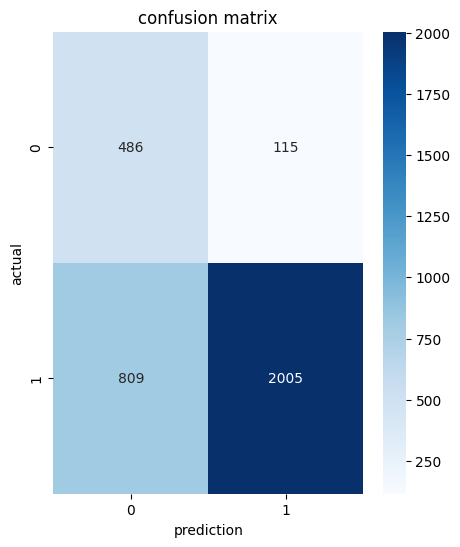

In [19]:
plt.figure(figsize=(5,6))
sns.heatmap(cm,annot=True,fmt='d',cmap='Blues')
plt.title('confusion matrix')
plt.xlabel('prediction')
plt.ylabel('actual')
plt.show()

In [20]:

import gradio as gr

def predict_loan_status(
    no_of_dependents, education, self_employed, income_annum,
    loan_amount, loan_term, cibil_score, residential_assets_value,
    commercial_assets_value, luxury_assets_value, bank_asset_value
):
    edu_val = 1 if education == "Graduate" else 0
    emp_val = 1 if self_employed == "Yes" else 0

    input_data = pd.DataFrame([[
        no_of_dependents, edu_val, emp_val, income_annum,
        loan_amount, loan_term, cibil_score, residential_assets_value,
        commercial_assets_value, luxury_assets_value, bank_asset_value
    ]], columns=X.columns)

    prediction = model.predict(input_data)[0]
    return "Approved" if prediction == 1 else "Rejected"

inputs = [
    gr.Number(label="Number of Dependents", value=1),
    gr.Radio(["Graduate", "Not Graduate"], label="Education"),
    gr.Radio(["Yes", "No"], label="Self Employed"),
    gr.Number(label="Annual Income ($)", value=5000000),
    gr.Number(label="Loan Amount ($)", value=15000000),
    gr.Number(label="Loan Term (Months)", value=12),
    gr.Number(label="CIBIL Score", value=750),
    gr.Number(label="Residential Assets Value ($)", value=2000000),
    gr.Number(label="Commercial Assets Value ($)", value=1000000),
    gr.Number(label="Luxury Assets Value ($)", value=5000000),
    gr.Number(label="Bank Asset Value ($)", value=3000000)
]

demo = gr.Interface(
    fn=predict_loan_status,
    inputs=inputs,
    outputs=gr.Textbox(label="Loan Status Result"),
    title="Loan Approval Prediction"
)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://b8f2808c99c9e01146.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
